# Titanic Prediction Project

In [1]:
import pandas as pd
import numpy as np

import matplotlib as plt
import seaborn as sns
from sklearn.metrics import accuracy_score

In [2]:
train = pd.read_csv('data/train.csv')
test = pd.read_csv('data/test.csv')

In [3]:
train.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [4]:
test.head()

,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,892,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292,NaN,Q
1,893,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.0,1,0,363272,7.0000,NaN,S
2,894,2,"Myles, Mr. Thomas Francis",male,62.0,0,0,240276,9.6875,NaN,Q
3,895,3,"Wirz, Mr. Albert",male,27.0,0,0,315154,8.6625,NaN,S
4,896,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",female,22.0,1,1,3101298,12.2875,NaN,S


### What is the majority class of Survived?

In [5]:
train['Survived'].value_counts()

Survived
0    549
1    342
Name: count, dtype: int64

In [6]:
actual = train['Survived']
prediction = np.zeros(len(train))
accuracy_score(actual, prediction)

0.6161616161616161

### Survived Rate by Sex

In [7]:
train.groupby('Sex')['Survived'].mean()

Sex
female    0.742038
male      0.188908
Name: Survived, dtype: float64

**Insight:** Female have a higher survival chance compared to male.

### Survival Rate by Pclass

In [8]:
train.groupby('Pclass', as_index=False)['Survived'].mean()

,Pclass,Survived
0,1,0.629630
1,2,0.472826
2,3,0.242363


### Survived data by Sex and Pclass

In [9]:
train.groupby(['Sex', 'Pclass'])['Survived'].agg(['mean', 'count'])

mean  count
Sex    Pclass                 
female 1       0.968085     94
       2       0.921053     76
       3       0.500000    144
male   1       0.368852    122
       2       0.157407    108
       3       0.135447    347

### Survival Rate by Title, create Title column

In [10]:
train['Title'] = train['Name'].str.split(',').str[1].str.split('.').str[0].apply(lambda x: x.strip())
test['Title'] = test['Name'].str.split(',').str[1].str.split('.').str[0].apply(lambda x: x.strip())
train.groupby(['Title'], as_index=False)['Survived'].agg(['mean', 'count'])

,Title,mean,count
0,Capt,0.000000,1
1,Col,0.500000,2
2,Don,0.000000,1
3,Dr,0.428571,7
4,Jonkheer,0.000000,1
5,Lady,1.000000,1
6,Major,0.500000,2
7,Master,0.575000,40
8,Miss,0.697802,182
9,Mlle,1.000000,2


**Insights:** Based on the count of these titles do grouping.

In [11]:
for df in [train, test]:
    df['Title'] = df['Title'].replace({'Mlle': 'Miss', 'Ms': 'Miss', 'Mme': 'Mrs'})
    df['Title'] = df['Title'].where(df['Title'].isin(['Mr', 'Mrs', 'Miss', 'Master']), 'Rare')

train.groupby('Title')['Survived'].agg(['mean', 'count'])

,mean,count
Title,,
Master,0.575000,40
Miss,0.702703,185
Mr,0.156673,517
Mrs,0.793651,126
Rare,0.347826,23


### Age Distribution by Survival

<Axes: xlabel='Age', ylabel='Count'>

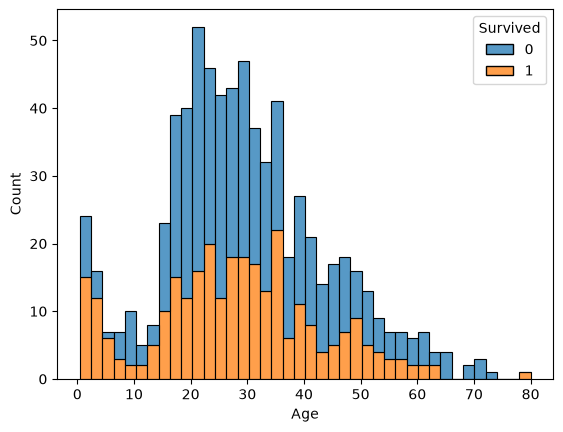

In [12]:
sns.histplot(data=train, x='Age', hue='Survived', bins = 40, multiple='stack')

**Insight:** Most passengers's age is between 20 and 36, but this group is too small which will shrinks the groups with other conditions.

### Survival Rate and Count by Embarked

In [13]:
train.groupby('Embarked')['Survived'].agg(['mean', 'count'])

,mean,count
Embarked,,
C,0.553571,168
Q,0.389610,77
S,0.336957,644


### Survived data by Sex, Pclass, and Embarked

In [14]:
train.groupby(['Sex', 'Pclass', 'Embarked'])['Survived'].agg(['mean', 'count'])

mean  count
Sex    Pclass Embarked                 
female 1      C         0.976744     43
              Q         1.000000      1
              S         0.958333     48
       2      C         1.000000      7
              Q         1.000000      2
              S         0.910448     67
       3      C         0.652174     23
              Q         0.727273     33
              S         0.375000     88
male   1      C         0.404762     42
              Q         0.000000      1
              S         0.354430     79
       2      C         0.200000     10
              Q         0.000000      1
              S         0.154639     97
       3      C         0.232558     43
              Q         0.076923     39
              S         0.128302    265

**Insight:** Passenger who is Female, Pclass is 1 or 2 is having a very high survival mean. Beside the female that embarked S, female in third class don't have a low survival mean compared to male.

## Rule-based Classifier

### Predict it with the patterns from the "Insight" above

In [15]:
actual = train['Survived']
prediction = ((train['Sex'] == 'female') & ~((train['Pclass'] == 3) & (train['Embarked'] == 'S'))).astype(int)

accuracy_score(actual, prediction)

0.8114478114478114

### Predict it with Female and first class

In [16]:
actual = train['Survived']
prediction = ((train['Sex'] == 'female') & (train['Pclass'] == 1)).astype(int)

accuracy_score(actual, prediction)

0.7149270482603816

**Insight:** The "Insight" patterns have a better accuracy score compared to this.

### Apply the patterns from "Insight" on the test dataframe as well

Rules applied: All the female besides those are both 3rd class and Embarked S.

In [17]:
test['Survived'] = ((test['Sex'] == 'female') & ~((test['Pclass'] == 3) & (test['Embarked'] == 'S'))).astype(int)


In [18]:
final_prediction = test[['PassengerId', 'Survived']]
final_prediction.head(10)

,PassengerId,Survived
0,892,0
1,893,0
2,894,0
3,895,0
4,896,0
5,897,0
6,898,1
7,899,0
8,900,1
9,901,0


In [19]:
final_prediction.to_csv('ian_prediction.csv', index=False)

**Insight:** The rule( All the famle besides those are both 3rd class and Embarked S)'s score: 0.77844 is greater than the baseline(0.75). It built by hand from patterns I found.

## Modeling

Try to improve the prediction by machine-learning models:

### Feature engineering

Use four feature groups: **sex × class**, **family size**, **travel groups** and **title**.

Age, Embarked, Cabin and Fare are dropped: Age and Cabin have many missing values, Embarked adds little once class is known, and Fare mostly repeats Pclass and the size of the ticket group.

#### 1. Sex × Class
**Reason:** Sex and class interact. Nearly all 1st/2nd-class women survived, 3rd-class women only about half, and men had low survival in every class. One flag per combination gives every model that interaction directly.

In [20]:
def sex_class(df):
    X = pd.DataFrame(index=df.index)
    for sex in ['female', 'male']:
        for pclass in [1, 2, 3]:
            X[f'{sex}_{pclass}'] = ((df['Sex'] == sex) & (df['Pclass'] == pclass)).astype(int)
    return X

#### 2. Family Size (with Alone and Large_Family)
**Reason:** Survival is not linear in family size. Small families (2–4) did best, while people travelling alone and large families (5+) did worse, so the two flags mark both ends.

In [21]:
def family(df):
    X = pd.DataFrame(index=df.index)
    X['Fam_Size'] = df['SibSp'] + df['Parch'] + 1
    X['Alone'] = (X['Fam_Size'] == 1).astype(int)
    X['Large_Family'] = (X['Fam_Size'] >= 5).astype(int)
    return X

#### 3. Travel Groups
**Reason:** Passengers on the same ticket travelled together even when not related (friends, maids, nannies), which SibSp/Parch miss. Ticket holders are counted across train and test to get the real group size. No Survived labels are used, so nothing leaks into CV.

In [22]:
ticket_counts = pd.concat([train['Ticket'], test['Ticket']]).value_counts()

def travel_group(df):
    X = pd.DataFrame(index=df.index)
    X['Group_Size'] = df['Ticket'].map(ticket_counts)
    X['Non_Family_Group'] = (X['Group_Size'] > df['SibSp'] + df['Parch'] + 1).astype(int)
    return X

#### 4. Title
**Reason:** Title adds age and status information the other groups don't have. "Master" marks young boys, who survived far more often than adult men, and "Mrs"/"Miss" separate married and unmarried women. In a 10×5-fold CV check, adding Title raised accuracy by about 3 points. Uses the grouped Title column from the analysis above (rare titles fall into the baseline).

In [23]:
def title(df):
    X = pd.DataFrame(index=df.index)
    for t in ['Mr', 'Mrs', 'Miss', 'Master']:
        X['Title:' + t] = (df['Title'] == t).astype(int)
    return X

Combine the groups into the model input.

In [24]:
feature_groups = {
    'Sex x Class': sex_class,
    'Family Size': family,
    'Travel Groups': travel_group,
    'Title': title,
}

def preprocess(df, groups=feature_groups):
    return pd.concat([make(df) for make in groups.values()], axis=1)

X, y, X_test = preprocess(train), train['Survived'], preprocess(test)
print(X.shape, X_test.shape)
print('Missing values (train, test):', X.isnull().sum().sum(), X_test.isnull().sum().sum())
X.head()

(891, 15) (418, 15)
Missing values (train, test): 0 0


,female_1,female_2,female_3,male_1,male_2,male_3,Fam_Size,Alone,Large_Family,Group_Size,Non_Family_Group,Title:Mr,Title:Mrs,Title:Miss,Title:Master
0,0,0,0,0,0,1,2,0,0,1,0,1,0,0,0
1,1,0,0,0,0,0,2,0,0,2,0,0,1,0,0
2,0,0,1,0,0,0,1,1,0,1,0,0,0,1,0
3,1,0,0,0,0,0,2,0,0,2,0,0,1,0,0
4,0,0,0,0,0,1,1,1,0,1,0,1,0,0,0


### Cross-validation Preparing

In [25]:
from sklearn.model_selection import cross_validate

results = {}
def evaluate(name, model):
    scores = cross_validate(model, X, y, cv=5, return_train_score=True)
    cv_acc = scores['test_score'].mean()
    gap = scores['train_score'].mean() - cv_acc
    results[name] = {'cv': cv_acc, 'gap': gap}
    print(name, 'cv:', round(cv_acc, 4), 'gap:', round(gap, 4))

cv is the average accuracy. Keeping tracking the gap(training accuracy - cv) to avoid overfitting.

### Models Comparing

In [26]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neural_network import MLPClassifier

models_n = {
    'Tree': DecisionTreeClassifier(max_depth=6, random_state=42),
    'LogRe': make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    'MLP': make_pipeline(StandardScaler(), MLPClassifier(hidden_layer_sizes=(31, ), max_iter=1000, early_stopping=True, solver='adam', random_state=42))
}

for name, model in models_n.items():
    evaluate(name, model)

Tree cv: 0.8093 gap: 0.0406


LogRe cv: 0.8328 gap: -0.0017


MLP cv: 0.8148 gap: 0.007


**Insight:** Logistic Regression has the highest cv with almost no gap. Decision Tree has the lowest cv and the largest gap.

## Ensemble Models / Methods:

### Simple Combination

In [27]:
from sklearn.ensemble import VotingClassifier

voting_model = VotingClassifier(list(models_n.items()), voting='soft')
evaluate('Voting', voting_model)

Voting cv: 0.8238 gap: 0.0205


### Bagging & Random Forest

In [28]:
from sklearn.ensemble import BaggingClassifier, RandomForestClassifier

bagging_model = BaggingClassifier(estimator=DecisionTreeClassifier(max_depth=6, random_state=42), n_estimators=200, random_state=42)

random_forest = RandomForestClassifier(n_estimators=300, max_depth=6, random_state=42)

evaluate('Bagging', bagging_model)
evaluate('Random Forest', random_forest)

Bagging cv: 0.8227 gap: 0.0337


Random Forest cv: 0.8316 gap: 0.0104


### Boosting

In [29]:
from sklearn.ensemble import AdaBoostClassifier

ada_model = AdaBoostClassifier(n_estimators=200, learning_rate=0.5, random_state=42)
evaluate('Ada_Boosted', ada_model)

Ada_Boosted cv: 0.8316 gap: 0.0006


### Stacking

In [30]:
from sklearn.ensemble import StackingClassifier

stack_model = StackingClassifier(
    estimators=[
        ('LogRe', models_n['LogRe']),
        ('Random Forest', random_forest),
        ('MLP', models_n['MLP']),
        ('Ada_Boosted', ada_model)
    ],
    final_estimator=LogisticRegression(max_iter=1000),
    cv=5
)

evaluate('Stacking', stack_model)

Stacking cv: 0.8316 gap: 0.0059


In [31]:
pd.DataFrame(results).T.sort_values('cv', ascending=False)

,cv,gap
LogRe,0.832754,-0.001667
Ada_Boosted,0.831630,0.000580
Random Forest,0.831624,0.010406
Stacking,0.831624,0.005917
Voting,0.823809,0.020467
Bagging,0.822685,0.033655
MLP,0.814795,0.007034
Tree,0.809271,0.040616


**Insight:** Stacking, Random Forest and AdaBoost tie at 0.832, just behind Logistic Regression. The ensembles don't beat a simple linear model on these features.

## Final Model: Logistic Regression on Feature Pairs

Multiply every pair of features together so a linear model can use interactions (for example 3rd-class female × large family). 15 features + 105 pairs = **120 inputs**.

An **L1 penalty** pushes the weights of useless pairs to exactly zero, so the model keeps only the ones that help. The penalty strength C is chosen with 10×5-fold repeated CV.

In [32]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.model_selection import GridSearchCV, RepeatedStratifiedKFold

rcv = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=42)

pair_model = make_pipeline(
    PolynomialFeatures(degree=2, interaction_only=True, include_bias=False),
    StandardScaler(),
    LogisticRegression(l1_ratio=1.0, solver='liblinear', max_iter=5000),
)
search = GridSearchCV(pair_model, {'logisticregression__C': [0.03, 0.05, 0.1, 0.2, 0.5]}, cv=rcv, n_jobs=-1)
search.fit(X, y)
print('best C:', search.best_params_['logisticregression__C'], '| 10x5 cv:', round(search.best_score_, 4))

pair_model = search.best_estimator_
evaluate('L1 Pairs', pair_model)

best C: 0.1 | 10x5 cv: 0.832
L1 Pairs cv: 0.8328 gap: 0.0


Which inputs did the L1 penalty keep? (sorted by weight size; positive = more likely to survive)

In [33]:
names = pair_model[0].get_feature_names_out(X.columns)
coef = pd.Series(pair_model[-1].coef_.ravel(), index=names)
kept = coef[coef != 0].sort_values(key=abs, ascending=False)
print(f'kept {len(kept)} of {len(coef)}')
kept.round(3)

kept 21 of 120


female_1                     0.798
male_3 Title:Mr             -0.605
Title:Mr                    -0.436
male_2                      -0.418
Large_Family Group_Size     -0.351
female_2                     0.294
Title:Master                 0.268
female_2 Fam_Size            0.230
Large_Family Title:Master   -0.228
male_2 Title:Master          0.208
Alone Group_Size             0.161
Large_Family                -0.089
male_2 Non_Family_Group     -0.087
male_1 Non_Family_Group     -0.067
female_2 Title:Miss          0.041
female_1 Large_Family        0.033
Alone Title:Mr              -0.032
Alone Title:Mrs              0.031
female_3 Large_Family       -0.022
male_2 Group_Size           -0.012
male_1 Title:Master          0.007
dtype: float64

In [34]:
pd.DataFrame(results).T.sort_values('cv', ascending=False)

,cv,gap
LogRe,0.832754,-0.001667
L1 Pairs,0.832754,0.000017
Ada_Boosted,0.831630,0.000580
Stacking,0.831624,0.005917
Random Forest,0.831624,0.010406
Voting,0.823809,0.020467
Bagging,0.822685,0.033655
MLP,0.814795,0.007034
Tree,0.809271,0.040616


**Insight:** The L1 pairs model ties for the best CV (0.833) with almost no gap (0.000), and it kept only **21 of 120** inputs. Every model landed within about 2 points (0.809–0.833), and the top five within 0.2 points, while changing the features moved accuracy by about 6 points (0.773 with Sex × Class alone → 0.833). **The features mattered, not the model.**

## Final Model for Submission

In [35]:
final_model = pair_model
final_model.fit(X, y)

final_submission = pd.DataFrame({'PassengerId': test['PassengerId'], 'Survived': final_model.predict(X_test)})
final_submission.to_csv('ian_final_prediction.csv', index=False)
final_submission['Survived'].value_counts()

Survived
0    254
1    164
Name: count, dtype: int64

## Feature Group Test

Add one feature group at a time and score each set with 10×5-fold repeated stratified CV (50 fits per bar), so a gain has to hold across many splits, not just one lucky fold. Error bars show the standard deviation across the 50 folds.

In [36]:
from sklearn.model_selection import RepeatedStratifiedKFold, cross_val_score

rcv = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=42)
test_models = {'LogRe': models_n['LogRe'], 'Random Forest': random_forest}

group_names = list(feature_groups)
rows = []
for k in range(1, len(group_names) + 1):
    label = group_names[0] if k == 1 else '+ ' + group_names[k - 1]
    X_step = preprocess(train, {n: feature_groups[n] for n in group_names[:k]})
    for model_name, model in test_models.items():
        scores = cross_val_score(model, X_step, y, cv=rcv)
        rows.append({'step': label, 'model': model_name, 'n_features': X_step.shape[1],
                     'cv': scores.mean(), 'std': scores.std()})

group_results = pd.DataFrame(rows)
group_results

,step,model,n_features,cv,std
0,Sex x Class,LogRe,6,0.772960,0.023228
1,Sex x Class,Random Forest,6,0.773072,0.023116
2,+ Family Size,LogRe,9,0.799893,0.023543
3,+ Family Size,Random Forest,9,0.804492,0.026975
4,+ Travel Groups,LogRe,11,0.795289,0.025069
5,+ Travel Groups,Random Forest,11,0.803931,0.024808
6,+ Title,LogRe,15,0.828844,0.024360
7,+ Title,Random Forest,15,0.831878,0.023164


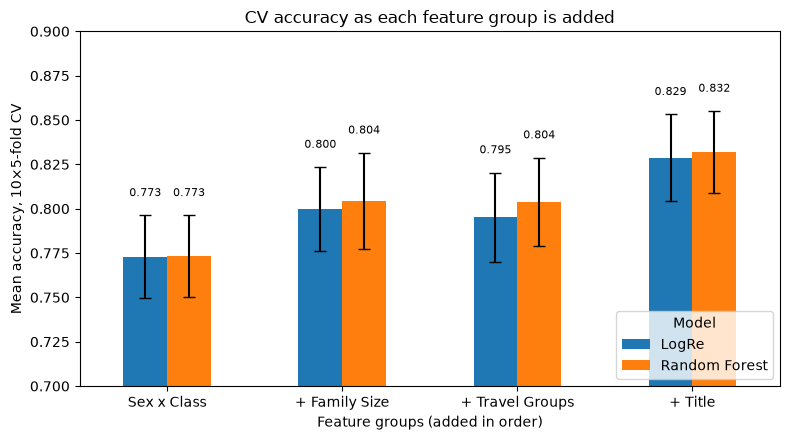

In [37]:
import matplotlib.pyplot as plt
from matplotlib.container import BarContainer

order = group_results['step'].unique()
means = group_results.pivot(index='step', columns='model', values='cv').loc[order]
stds = group_results.pivot(index='step', columns='model', values='std').loc[order]

ax = means.plot.bar(yerr=stds, capsize=4, rot=0, figsize=(8, 4.5))
for bars in ax.containers:
    if isinstance(bars, BarContainer):
        ax.bar_label(bars, fmt='%.3f', padding=12, fontsize=8)
ax.set_ylim(0.70, 0.90)
ax.set_xlabel('Feature groups (added in order)')
ax.set_ylabel('Mean accuracy, 10×5-fold CV')
ax.set_title('CV accuracy as each feature group is added')
ax.legend(title='Model', loc='lower right')
plt.tight_layout()
plt.show()